# 18 水下图像：合成退化、增强与评价边界

用随附真实水果照片模拟色偏、衰减与雾化，再做灰世界白平衡和 CLAHE。输入 → 退化过程 → 增强输出全部可见。
**照片不是真实水下采集，退化模型是教学简化模型。** 只有在这个已知参考的合成实验中，才适合直接对参考图算 PSNR/SSIM 类指标。
真实水下通常没有无退化真值；色彩好看或无参考分数提高，不等于恢复了真实颜色或提升了检测性能。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder)); break
else:
    raise FileNotFoundError("请从课程项目根目录或 notebooks 目录启动 Jupyter。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass
import numpy as np
import matplotlib.pyplot as plt
import cv2
import torch
from torch import nn
torch.set_num_threads(min(2, os.cpu_count() or 1))
DEVICE = device()
print("计算设备：", DEVICE)


计算设备： cuda


## 1. 真实原图、RGB 矩阵与颜色范围

OpenCV 读入 BGR，要转换成 RGB 再显示。统一转换为 float32 的 0–1，防止 uint8 乘加溢出。
课程随附 OpenCV `fruits.jpg`；不需要联网下载。


输入： (240, 320, 3) float32
左上角 RGB 矩阵：
 [[[0.524 0.254 0.062]
  [0.53  0.252 0.062]
  [0.527 0.241 0.055]]

 [[0.548 0.25  0.067]
  [0.541 0.239 0.058]
  [0.534 0.226 0.047]]

 [[0.56  0.238 0.064]
  [0.55  0.228 0.054]
  [0.545 0.222 0.048]]]


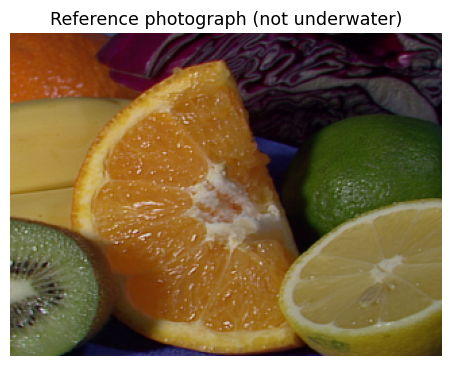

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/18_underwater_reference.png')

In [2]:
photo_path=ROOT/"assets/photos/fruits.jpg"
bgr=cv2.imread(str(photo_path))
if bgr is None: raise FileNotFoundError(f"缺少随附照片：{photo_path}")
reference=cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB).astype(np.float32)/255
reference=cv2.resize(reference,(320,240),interpolation=cv2.INTER_AREA)
print("输入：",reference.shape,reference.dtype)
print("左上角 RGB 矩阵：\n",np.round(reference[:3,:3],3))
plt.figure(figsize=(6,4)); plt.imshow(reference); plt.title("Reference photograph (not underwater)"); plt.axis("off")
save_figure("18_underwater_reference.png")


## 2. 可观察的合成退化过程

简化形式 $I_c=J_c t_c + A_c(1-t_c)$，其中 $J$ 是参考、$t$ 是通道透射率、$A$ 是背景光。
红通道衰减更强，且模拟深度从左到右增加。它用于理解现象，不能表示所有真实水域或相机成像。


透射率 RGB（左/中/右）：
 [[0.527 0.771 0.869]
 [0.201 0.521 0.704]
 [0.077 0.353 0.571]]


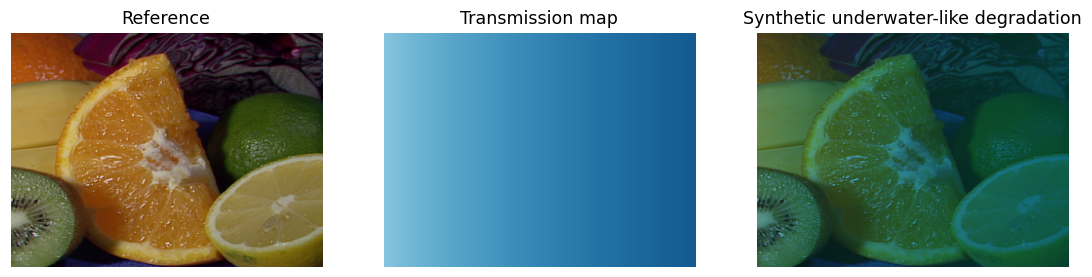

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/18_underwater_degradation.png')

In [3]:
h,w=reference.shape[:2]
depth=np.linspace(.4,1.6,w,dtype=np.float32)[None,:,None]
beta=np.array([1.6,.65,.35],np.float32)[None,None,:]
transmission=np.exp(-depth*beta)
ambient=np.array([.02,.30,.36],np.float32)[None,None,:]
degraded=np.clip(reference*transmission+ambient*(1-transmission),0,1)
print("透射率 RGB（左/中/右）：\n",np.round(transmission[0,[0,w//2,-1]],3))
fig,axs=plt.subplots(1,3,figsize=(13,4))
axs[0].imshow(reference); axs[0].set_title("Reference")
axs[1].imshow(np.broadcast_to(transmission,(h,w,3))); axs[1].set_title("Transmission map")
axs[2].imshow(degraded); axs[2].set_title("Synthetic underwater-like degradation")
for ax in axs: ax.axis("off")
save_figure("18_underwater_degradation.png")


## 3. 灰世界白平衡

假设场景平均颜色应该接近灰色，按各通道均值的倒数调整增益。若场景本来大面积是绿色/红色，这个假设就会失效。
因此增益做了限制，并保留数值供检查，而不是盲目追求更鲜艳。


退化图 RGB 均值： [0.127 0.324 0.234] 增益： [1.796 0.705 0.976]
白平衡输出局部：
 [[0.509 0.495 0.46 ]
 [0.507 0.502 0.496]
 [0.474 0.475 0.477]]


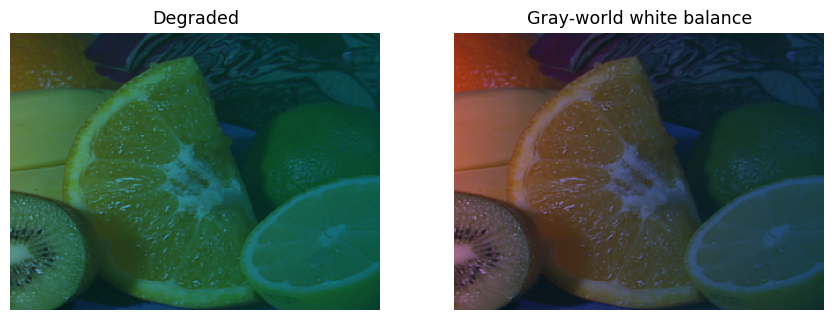

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/18_underwater_white_balance.png')

In [4]:
means=degraded.mean(axis=(0,1))
gain=np.clip(means.mean()/np.maximum(means,1e-6),.4,3.)
balanced=np.clip(degraded*gain,0,1)
print("退化图 RGB 均值：",np.round(means,3),"增益：",np.round(gain,3))
print("白平衡输出局部：\n",np.round(balanced[40:43,40:43,0],3))
fig,axs=plt.subplots(1,2,figsize=(10,4))
axs[0].imshow(degraded); axs[0].set_title("Degraded")
axs[1].imshow(balanced); axs[1].set_title("Gray-world white balance")
for ax in axs: ax.axis("off")
save_figure("18_underwater_white_balance.png")


## 4. 在 Lab 亮度上做 CLAHE

局部直方图均衡化改变明暗对比度，不直接逆转物理衰减。只处理 L 通道以减少额外的颜色失真。
过大的 clipLimit 可能放大噪声和边缘光晕。


输入 L 局部：
 [[93 89 83 80]
 [94 93 92 92]
 [81 81 82 82]
 [80 81 81 79]]
输出 L 局部：
 [[131 122 109 103]
 [132 131 130 131]
 [100 102 105 106]
 [ 97 101 102  98]]


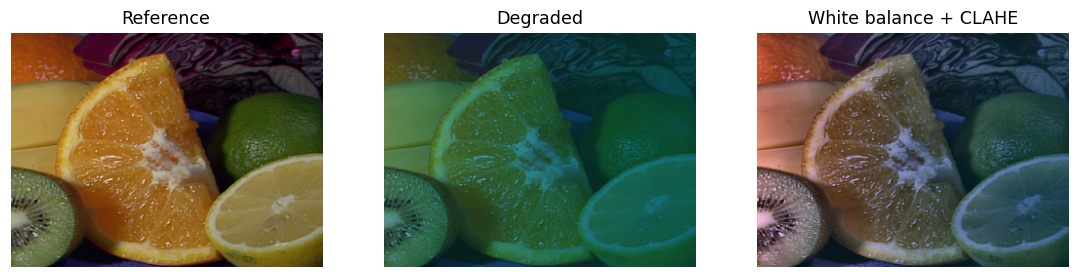

PosixPath('/ds1/workspace/CV/cv-beginner-course/outputs/18_underwater_results.png')

In [5]:
balanced_u8=np.uint8(np.round(balanced*255))
lab=cv2.cvtColor(balanced_u8,cv2.COLOR_RGB2LAB)
clahe=cv2.createCLAHE(clipLimit=2.,tileGridSize=(8,8))
lab_out=lab.copy(); lab_out[:,:,0]=clahe.apply(lab[:,:,0])
enhanced=cv2.cvtColor(lab_out,cv2.COLOR_LAB2RGB).astype(np.float32)/255
print("输入 L 局部：\n",lab[40:44,40:44,0])
print("输出 L 局部：\n",lab_out[40:44,40:44,0])
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,im,title in zip(axs,[reference,degraded,enhanced],["Reference","Degraded","White balance + CLAHE"]):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
save_figure("18_underwater_results.png")


## 5. 与已知参考比较，同时报告不利结果

PSNR 使用相同 0–1 范围：$10\log_{10}(1/MSE)$。数值越高意味着本实验中逐像素误差越小，不衡量语义正确性。
增强后的 PSNR 可能下降，这不是程序失败，而是对比增强和参考重建目标不同。
下面也报告通道均值和亮度标准差；它们仅是描述统计，不能代替 UCIQE/UIQM 或下游目标检测评价。


degraded        PSNR=13.54 dB, luminance std=0.086, RGB mean=[0.127 0.324 0.234]
white_balance   PSNR=15.16 dB, luminance std=0.087, RGB mean=[0.229 0.229 0.229]
enhanced        PSNR=16.48 dB, luminance std=0.129, RGB mean=[0.298 0.295 0.295]


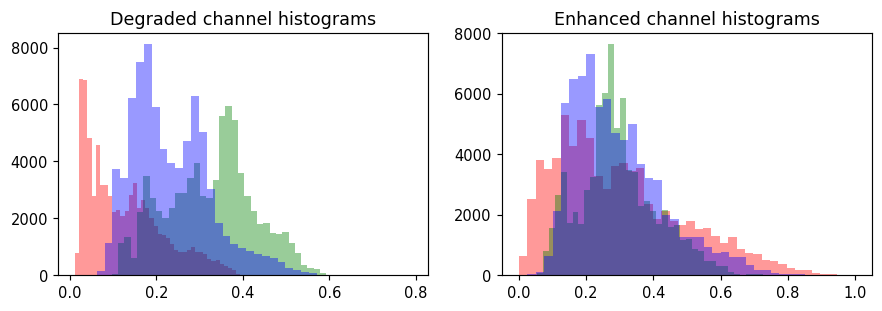

In [6]:
def psnr(a,b):
    mse=float(np.mean((a-b)**2))
    return float("inf") if mse==0 else 10*np.log10(1/mse)
def luminance_std(im):
    return float((im@np.array([.299,.587,.114])).std())
for label,im in [("degraded",degraded),("white_balance",balanced),("enhanced",enhanced)]:
    print(f"{label:15s} PSNR={psnr(reference,im):.2f} dB, luminance std={luminance_std(im):.3f}, RGB mean={im.mean((0,1)).round(3)}")
fig,axs=plt.subplots(1,2,figsize=(10,3))
for c,color in enumerate(["r","g","b"]):
    axs[0].hist(degraded[:,:,c].ravel(),bins=40,alpha=.4,color=color)
    axs[1].hist(enhanced[:,:,c].ravel(),bins=40,alpha=.4,color=color)
axs[0].set_title("Degraded channel histograms"); axs[1].set_title("Enhanced channel histograms")
save_figure("18_underwater_histograms.png")
assert enhanced.shape==reference.shape and np.isfinite(enhanced).all()


## 6. 物理模型的“已知参数上界”与实际边界

在本合成实验中，生成时的 $t,A$ 已知，可以代数求逆来检验实现。真实图像的参数通常未知，估计误差和噪声会被放大。
此步骤是验证合成过程，不是可直接部署的真实水下恢复算法。


已知合成参数的逆变换最大误差： 1.1920928955078125e-07


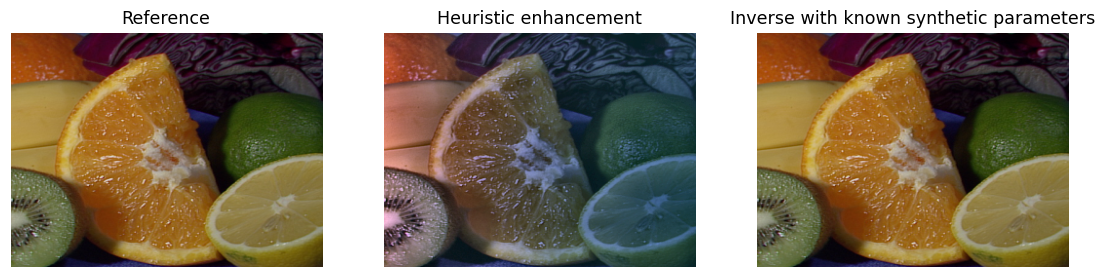

In [7]:
oracle=np.clip((degraded-ambient*(1-transmission))/transmission,0,1)
print("已知合成参数的逆变换最大误差：",float(np.abs(oracle-reference).max()))
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,im,title in zip(axs,[reference,enhanced,oracle],["Reference","Heuristic enhancement","Inverse with known synthetic parameters"]):
    ax.imshow(im); ax.set_title(title); ax.axis("off")
save_figure("18_underwater_oracle.png")
assert np.allclose(oracle,reference,atol=1e-5)


## 7. 练习与真实水下研究路线

练习：增大红通道衰减、加入噪声，比较增强效果；使用全绿色场景观察灰世界假设失败；如果有检测标注，分别对增强前后计算同一模型的 mAP，验证增强是否真正帮助任务。
后续可比较 UIEB 等有参考数据集与真实无参考数据；记录数据许可与划分。cGAN 是**条件生成对抗网络**，不应称为强化学习。

来源：[OpenCV CLAHE](https://docs.opencv.org/4.x/d5/daf/tutorial_py_histogram_equalization.html)、[UIEB 官方项目](https://li-chongyi.github.io/proj_benchmark.html)、[Conditional GAN 原论文](https://arxiv.org/abs/1411.1784)。本课为可解释的传统基线，不声称复现水下深度恢复模型。
